In [2]:
!unzip -o telco.zip

Archive:  telco.zip
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


In [3]:
import glob
import numpy as np
import pandas as pd

# ---------- 1. LOAD + CLEAN ----------
path = glob.glob("*Telco*Churn*.csv")[0]
df = pd.read_csv(path)
print("File:", path, "| rows, columns:", df.shape)
print("Duplicate customers:", df["customerID"].duplicated().sum())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip().replace("", np.nan), errors="coerce")
print("Blank TotalCharges (new customers, tenure 0):", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["Senior"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["AddOnCount"] = (df[addons] == "Yes").sum(axis=1)
df["TenureBand"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                          labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])

# ---------- 2. HEADLINE NUMBERS ----------
total, churned = len(df), int(df["ChurnFlag"].sum())
mrr = df["MonthlyCharges"].sum()
lost = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].sum()
print(f"\nCustomers: {total} | Churned: {churned} | Churn rate: {churned / total * 100:.2f}%")
print(f"Monthly recurring revenue (all): ${mrr:,.0f} | Lost to churn: ${lost:,.0f} ({lost / mrr * 100:.1f}% of MRR)")
print(f"Avg monthly charge: churned ${df.loc[df.ChurnFlag == 1, 'MonthlyCharges'].mean():.2f} vs stayed ${df.loc[df.ChurnFlag == 0, 'MonthlyCharges'].mean():.2f}")
print(f"Avg tenure: churned {df.loc[df.ChurnFlag == 1, 'tenure'].mean():.1f} m vs stayed {df.loc[df.ChurnFlag == 0, 'tenure'].mean():.1f} m")

# ---------- 3. CHURN BY SEGMENT ----------
def seg(col):
    t = df.groupby(col, observed=True).agg(Customers=("ChurnFlag", "size"), Churned=("ChurnFlag", "sum"),
                                           ChurnRate=("ChurnFlag", "mean"), AvgMonthly=("MonthlyCharges", "mean"))
    t["ChurnRate"] = (t["ChurnRate"] * 100).round(1)
    t["AvgMonthly"] = t["AvgMonthly"].round(1)
    return t

seg_cols = ["Contract", "InternetService", "PaymentMethod", "TenureBand", "Senior", "PaperlessBilling",
            "TechSupport", "OnlineSecurity", "AddOnCount"]
for c in seg_cols:
    print(f"\n--- {c}"); print(seg(c))

File: WA_Fn-UseC_-Telco-Customer-Churn.csv | rows, columns: (7043, 21)
Duplicate customers: 0
Blank TotalCharges (new customers, tenure 0): 11

Customers: 7043 | Churned: 1869 | Churn rate: 26.54%
Monthly recurring revenue (all): $456,117 | Lost to churn: $139,131 (30.5% of MRR)
Avg monthly charge: churned $74.44 vs stayed $61.27
Avg tenure: churned 18.0 m vs stayed 37.6 m

--- Contract
                Customers  Churned  ChurnRate  AvgMonthly
Contract                                                 
Month-to-month       3875     1655       42.7        66.4
One year             1473      166       11.3        65.0
Two year             1695       48        2.8        60.8

--- InternetService
                 Customers  Churned  ChurnRate  AvgMonthly
InternetService                                           
DSL                   2421      459       19.0        58.1
Fiber optic           3096     1297       41.9        91.5
No                    1526      113        7.4        21.1

---

In [4]:
# ---------- 4. COHORTS: contract x tenure band ----------
cohort = df.pivot_table(index="Contract", columns="TenureBand", values="ChurnFlag", aggfunc="mean", observed=True) * 100
cohort_n = df.pivot_table(index="Contract", columns="TenureBand", values="ChurnFlag", aggfunc="size", observed=True)
print("\nCOHORT CHURN RATE % (contract x tenure band)"); print(cohort.round(1))
print("\nCOHORT SIZES"); print(cohort_n)

# ---------- 5. RETENTION CURVES (Kaplan-Meier) ----------
def km(d):
    s, out = 1.0, []
    for m in range(1, 73):
        at_risk = (d["tenure"] >= m).sum()
        events = ((d["tenure"] == m) & (d["ChurnFlag"] == 1)).sum()
        if at_risk > 0:
            s *= 1 - events / at_risk
        out.append(s)
    return pd.Series(out, index=range(1, 73))

curves = {"All customers": km(df)}
for k in ["Month-to-month", "One year", "Two year"]:
    curves[k] = km(df[df["Contract"] == k])
curves = pd.DataFrame(curves)
print("\nRETENTION (share still active) at month:")
print((curves.loc[[3, 6, 12, 24, 36, 60]] * 100).round(1))

# ---------- 6. THE EARLY-CHURN CLIFF ----------
c = df[df["ChurnFlag"] == 1]
print(f"\nChurners who left within 6 months: {(c.tenure <= 6).mean() * 100:.1f}% | within 12 months: {(c.tenure <= 12).mean() * 100:.1f}%")
by_month = c.groupby("tenure").size().reindex(range(0, 73), fill_value=0)
print("Customers lost at tenure month 1:", int(by_month.loc[1]), "| month 72:", int(by_month.loc[72]))

# ---------- 7. REVENUE LOST BY CONTRACT ----------
rev = df[df["ChurnFlag"] == 1].groupby("Contract")["MonthlyCharges"].agg(["size", "sum"]).rename(columns={"size": "ChurnedCustomers", "sum": "LostMonthlyRevenue"})
rev["Share_%"] = (rev["LostMonthlyRevenue"] / rev["LostMonthlyRevenue"].sum() * 100).round(1)
rev["LostMonthlyRevenue"] = rev["LostMonthlyRevenue"].round(0)
print("\nLOST MONTHLY REVENUE BY CONTRACT"); print(rev)

# ---------- 8. RISKY PROFILE ----------
risky = df[(df["Contract"] == "Month-to-month") & (df["tenure"] <= 12) & (df["InternetService"] == "Fiber optic")]
print(f"\nMonth-to-month + fibre + first year: {len(risky)} customers ({len(risky) / total * 100:.1f}% of base), churn {risky.ChurnFlag.mean() * 100:.1f}%")


COHORT CHURN RATE % (contract x tenure band)
TenureBand      0-6 m  7-12 m  13-24 m  25-48 m  49-72 m
Contract                                                
Month-to-month   55.2    42.0     37.7     32.9     26.0
One year         10.3    10.6      8.1     10.6     12.9
Two year          0.0     0.0      0.0      2.2      3.3

COHORT SIZES
TenureBand      0-6 m  7-12 m  13-24 m  25-48 m  49-72 m
Contract                                                
Month-to-month   1413     581      737      802      342
One year           39      85      197      518      634
Two year           29      39       90      274     1263

RETENTION (share still active) at month:
    All customers  Month-to-month  One year  Two year
3            91.4            84.2      99.9     100.0
6            88.5            78.6      99.7     100.0
12           84.3            70.3      99.1     100.0
24           78.9            58.6      97.8     100.0
36           74.9            49.1      95.9      99.9
60  

Model AUC on unseen customers: 0.845

BIGGEST CHURN BOOSTERS (higher = more churn):
PaymentMethod_Electronic check    0.35
MultipleLines_Yes                 0.37
StreamingTV_Yes                   0.37
PaperlessBilling_Yes              0.40
StreamingMovies_Yes               0.43
InternetService_Fiber optic       1.18
dtype: float64

BIGGEST CHURN REDUCERS:
Contract_Two year    -1.26
tenure               -0.79
Contract_One year    -0.69
PhoneService_Yes     -0.46
MonthlyCharges       -0.36
OnlineSecurity_Yes   -0.35
dtype: float64

Active customers: 5174 | high risk (>=50%): 530 worth $43,043/month
Expected monthly revenue at risk (all active): $67,534
customerID       Contract  tenure InternetService    PaymentMethod  MonthlyCharges  ChurnRisk  ExpectedMonthlyLoss
3292-PBZEJ Month-to-month      11     Fiber optic Electronic check          111.40       0.74                82.89
5150-ITWWB Month-to-month       3     Fiber optic Electronic check           94.85       0.86                81

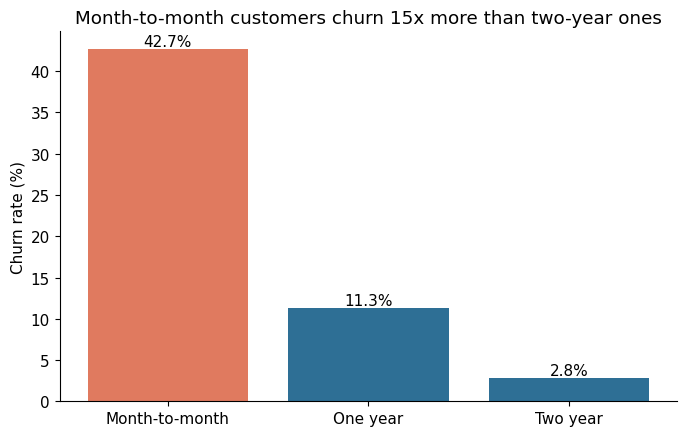

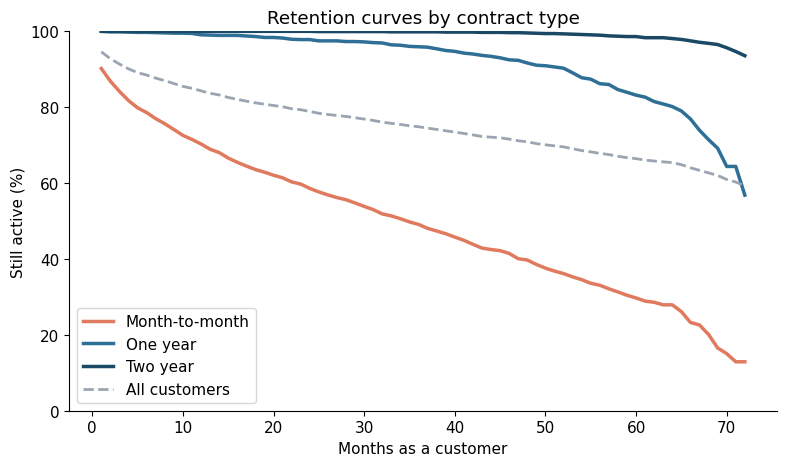

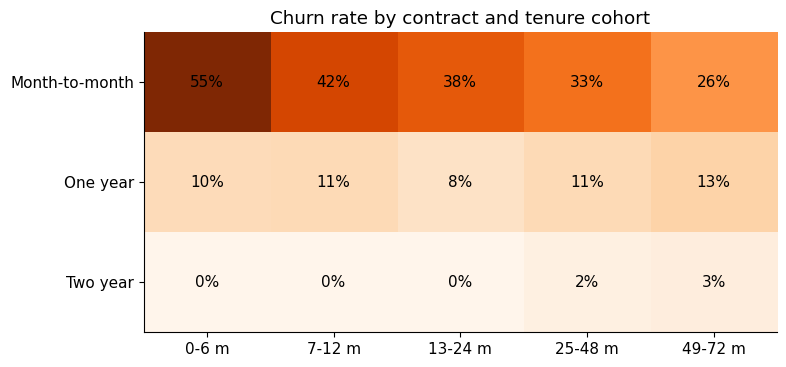

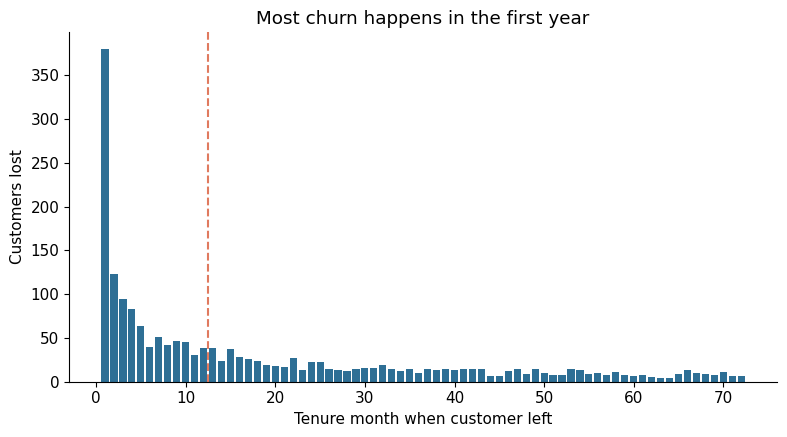

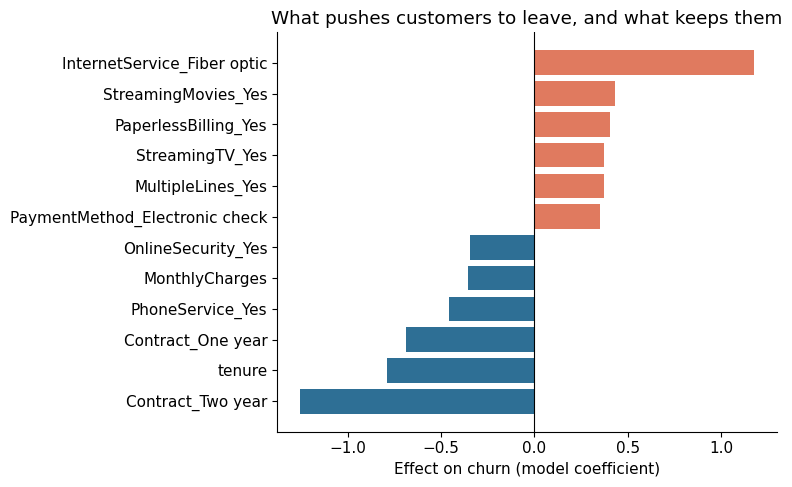

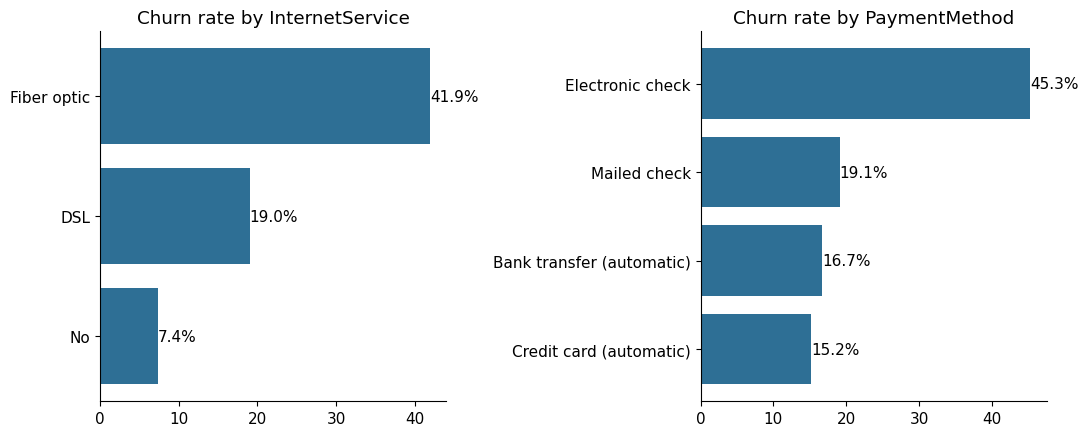


Saved: 8 tables + 6 charts -> FUTURE_DS_02_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# ---------- 9. WHAT DRIVES CHURN? (logistic regression) ----------
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "Senior", "Partner", "Dependents",
            "TechSupport", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies",
            "MultipleLines", "PhoneService", "gender"]
num_cols = ["tenure", "MonthlyCharges"]
X = pd.get_dummies(df[cat_cols], drop_first=True).astype(float)
X[num_cols] = StandardScaler().fit_transform(df[num_cols])
y = df["ChurnFlag"]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
model = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print("Model AUC on unseen customers:", round(roc_auc_score(yte, model.predict_proba(Xte)[:, 1]), 3))

coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
print("\nBIGGEST CHURN BOOSTERS (higher = more churn):"); print(coef.tail(6).round(2))
print("\nBIGGEST CHURN REDUCERS:"); print(coef.head(6).round(2))

# ---------- 10. WHO TO CALL FIRST: at-risk active customers ----------
final = LogisticRegression(max_iter=2000).fit(X, y)
active = df[df["ChurnFlag"] == 0].copy()
active["ChurnRisk"] = final.predict_proba(X.loc[active.index])[:, 1]
active["ExpectedMonthlyLoss"] = active["ChurnRisk"] * active["MonthlyCharges"]
callist = active.sort_values("ExpectedMonthlyLoss", ascending=False)[
    ["customerID", "Contract", "tenure", "InternetService", "PaymentMethod", "MonthlyCharges", "ChurnRisk", "ExpectedMonthlyLoss"]]
high = active[active["ChurnRisk"] >= 0.5]
print(f"\nActive customers: {len(active)} | high risk (>=50%): {len(high)} worth ${high.MonthlyCharges.sum():,.0f}/month")
print(f"Expected monthly revenue at risk (all active): ${active.ExpectedMonthlyLoss.sum():,.0f}")
print(callist.head(5).round(2).to_string(index=False))

# ---------- 11. WHAT-IF: move month-to-month customers to a 1-year plan ----------
m2m = df[df["Contract"] == "Month-to-month"]
r_m2m = m2m["ChurnFlag"].mean(); r_1y = df.loc[df["Contract"] == "One year", "ChurnFlag"].mean()
moved = int(len(m2m) * 0.10)
saved = moved * (r_m2m - r_1y)
mrr_saved = saved * m2m["MonthlyCharges"].mean()
print(f"\nWHAT-IF: move 10% of month-to-month customers ({moved}) to 1-year plans")
print(f"Churn {r_m2m * 100:.1f}% -> {r_1y * 100:.1f}% | customers kept: {saved:.0f} | monthly revenue kept: ${mrr_saved:,.0f} (${mrr_saved * 12:,.0f}/year)")

# ---------- 12. CHARTS (saved as PNG) ----------
import os
import matplotlib.pyplot as plt
os.makedirs("charts", exist_ok=True)
BLUE, ORANGE, GREY = "#2E6F95", "#E07A5F", "#9AA5B1"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

t = seg("Contract")["ChurnRate"]
fig, ax = plt.subplots(figsize=(7, 4.5)); bars = ax.bar(t.index, t.values, color=[ORANGE, BLUE, BLUE])
ax.bar_label(bars, fmt="%.1f%%"); ax.set_ylabel("Churn rate (%)"); ax.set_title("Month-to-month customers churn 15x more than two-year ones")
plt.tight_layout(); plt.savefig("charts/01_churn_by_contract.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
for name, col in [("Month-to-month", ORANGE), ("One year", BLUE), ("Two year", "#1B4965")]:
    ax.plot(curves.index, curves[name] * 100, label=name, color=col, lw=2.5)
ax.plot(curves.index, curves["All customers"] * 100, label="All customers", color=GREY, lw=2, ls="--")
ax.set_xlabel("Months as a customer"); ax.set_ylabel("Still active (%)"); ax.set_ylim(0, 100); ax.legend()
ax.set_title("Retention curves by contract type"); plt.tight_layout(); plt.savefig("charts/02_retention_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8)); im = ax.imshow(cohort.values, cmap="Oranges", aspect="auto")
ax.set_xticks(range(len(cohort.columns))); ax.set_xticklabels(cohort.columns); ax.set_yticks(range(len(cohort.index))); ax.set_yticklabels(cohort.index)
for i in range(cohort.shape[0]):
    for j in range(cohort.shape[1]):
        ax.text(j, i, f"{cohort.values[i, j]:.0f}%", ha="center", va="center", color="black")
ax.set_title("Churn rate by contract and tenure cohort"); plt.tight_layout(); plt.savefig("charts/03_cohort_heatmap.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5)); ax.bar(by_month.index[1:], by_month.values[1:], color=BLUE)
ax.axvline(12.5, color=ORANGE, ls="--"); ax.set_xlabel("Tenure month when customer left"); ax.set_ylabel("Customers lost")
ax.set_title("Most churn happens in the first year"); plt.tight_layout(); plt.savefig("charts/04_early_churn_cliff.png", dpi=150); plt.show()

top = pd.concat([coef.head(6), coef.tail(6)])
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(top.index, top.values, color=[BLUE if v < 0 else ORANGE for v in top.values])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Effect on churn (model coefficient)"); ax.set_title("What pushes customers to leave, and what keeps them")
plt.tight_layout(); plt.savefig("charts/05_churn_drivers.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["InternetService", "PaymentMethod"]):
    s = seg(col)["ChurnRate"].sort_values(); bars = ax.barh(s.index, s.values, color=BLUE); ax.bar_label(bars, fmt="%.1f%%"); ax.set_title(f"Churn rate by {col}")
plt.tight_layout(); plt.savefig("charts/06_other_segments.png", dpi=150); plt.show()

# ---------- 13. SAVE EVERYTHING AS ONE ZIP ----------
import zipfile
from google.colab import files
tables = {"churn_by_contract.csv": seg("Contract"), "churn_by_internet.csv": seg("InternetService"), "churn_by_payment.csv": seg("PaymentMethod"),
          "churn_by_tenure_band.csv": seg("TenureBand"), "cohort_churn_rate.csv": cohort.round(1), "retention_curves.csv": (curves * 100).round(2),
          "lost_revenue_by_contract.csv": rev, "at_risk_customers.csv": callist.round(3)}
with zipfile.ZipFile("FUTURE_DS_02_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name, tab in tables.items():
        tab.to_csv(name); z.write(name)
    for f in sorted(os.listdir("charts")):
        z.write(f"charts/{f}")
print("\nSaved:", len(tables), "tables +", len(os.listdir("charts")), "charts -> FUTURE_DS_02_outputs.zip")
files.download("FUTURE_DS_02_outputs.zip")